# Project 4: Knowledge Distillation for Lightweight Models (Fashion-MNIST)
Teacher CNN -> small student CNN. Compare: student (labels only) vs student (distilled).
Open in VS Code / Jupyter (the `# %%` markers are cells), or just run: `python kd_fashion_mnist.py`

**Problem statement:** can a compact student learn from a larger teacher's soft targets and
beat the same student trained only on ground-truth labels?

In [1]:
import os, io, time, random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from torchvision import datasets
from sklearn.metrics import f1_score, confusion_matrix

SEED = 42
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)

set_seed(SEED)
os.makedirs("figures", exist_ok=True)
CLASSES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
           "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
print("torch", torch.__version__, "| threads:", torch.get_num_threads(), "| device: cpu")

torch 2.15.0 | threads: 4 | device: cpu


## 1. Dataset documentation
Fashion-MNIST (Zalando Research, Xiao et al. 2017, https://github.com/zalandoresearch/fashion-mnist).
70,000 grayscale 28x28 images, 10 balanced classes. Official split: 60k train / 10k test.
We further hold out 5k of train as **validation** (for model selection). Target = clothing class.
Limitations: low-res, centred, clean images; MNIST-like benchmark, so differences between models are small.

In [ ]:

tr = datasets.FashionMNIST("data", train=True, download=True)
te = datasets.FashionMNIST("data", train=False, download=True)

#data folder gets made , when we run the above two lines 
#data folder contains -> training images , training labels , test images, test labels 

X_all = tr.data.float().div(255).unsqueeze(1)
y_all = tr.targets
Xte_raw = te.data.float().div(255).unsqueeze(1)
yte = te.targets


#divide into 5000 for validation
g = torch.Generator().manual_seed(SEED)
perm = torch.randperm(len(X_all), generator=g)
val_idx, tr_idx = perm[:5000], perm[5000:]

Xtr_raw, ytr = X_all[tr_idx], y_all[tr_idx]
Xva_raw, yva = X_all[val_idx], y_all[val_idx]

# normalisation stats from TRAIN split only (no leakage)
MEAN, STD = Xtr_raw.mean().item(), Xtr_raw.std().item()
norm = lambda x: (x - MEAN) / STD
Xtr, Xva, Xte = norm(Xtr_raw), norm(Xva_raw), norm(Xte_raw)
print(f"train {tuple(Xtr.shape)} | val {tuple(Xva.shape)} | test {tuple(Xte.shape)} | mean={MEAN:.4f} std={STD:.4f}")

train (55000, 1, 28, 28) | val (5000, 1, 28, 28) | test (10000, 1, 28, 28) | mean=0.2859 std=0.3529


## 2. EDA (3+ analyses)

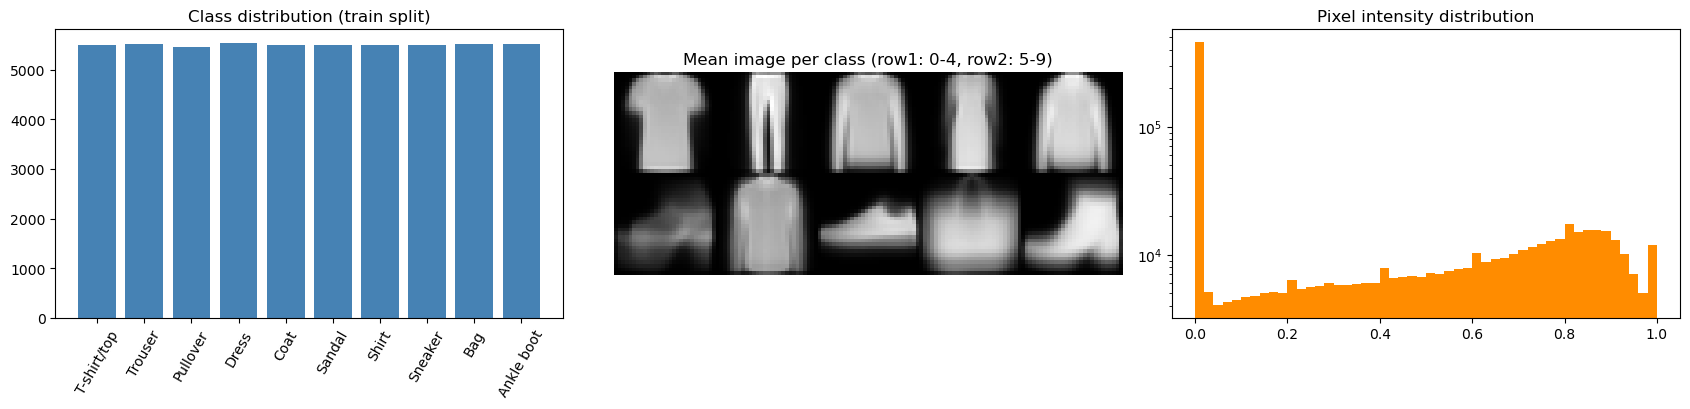

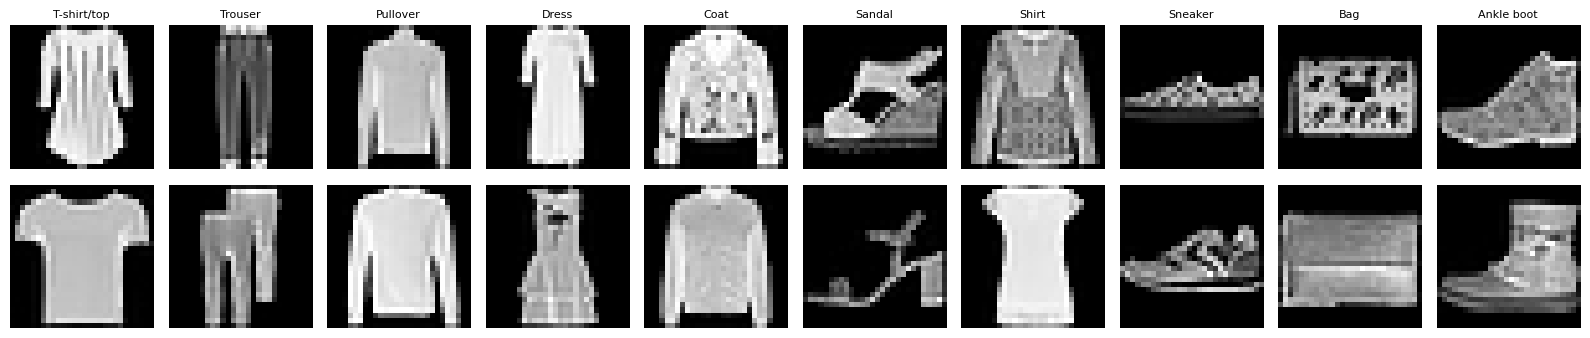

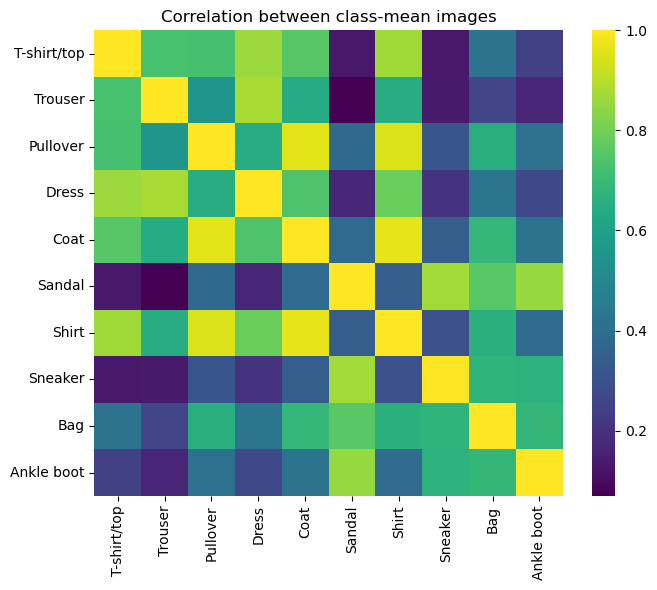

Missing values: none (fixed-size uint8 images). Interpretation: balanced classes, so accuracy is a fair metric, but macro-F1 is still reported; upper-body garments look alike -> expected failure cases.


In [3]:
# (a) class balance
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
counts = pd.Series(ytr.numpy()).value_counts().sort_index()
ax[0].bar([CLASSES[i] for i in counts.index], counts.values, color="steelblue")
ax[0].set_title("Class distribution (train split)"); ax[0].tick_params(axis="x", rotation=60)

# (b) mean image per class
mean_imgs = torch.stack([Xtr_raw[ytr == c].mean(0).squeeze() for c in range(10)])
grid = torch.cat([torch.cat(list(mean_imgs[:5]), 1), torch.cat(list(mean_imgs[5:]), 1)], 0)
ax[1].imshow(grid, cmap="gray"); ax[1].axis("off"); ax[1].set_title("Mean image per class (row1: 0-4, row2: 5-9)")

# (c) pixel intensity distribution
ax[2].hist(Xtr_raw.flatten().numpy()[::50], bins=50, color="darkorange")
ax[2].set_title("Pixel intensity distribution"); ax[2].set_yscale("log")
plt.tight_layout(); plt.savefig("figures/eda_overview.png", dpi=150); plt.show()

# (d) sample images
fig, axes = plt.subplots(2, 10, figsize=(16, 3.6))
for c in range(10):
    ids = (ytr == c).nonzero().flatten()[:2]
    for r, i in enumerate(ids):
        axes[r, c].imshow(Xtr_raw[i].squeeze(), cmap="gray"); axes[r, c].axis("off")
        if r == 0: axes[r, c].set_title(CLASSES[c], fontsize=8)
plt.tight_layout(); plt.savefig("figures/eda_samples.png", dpi=150); plt.show()

# (e) similarity of class means -> predicts which classes will be confused (shirt/T-shirt/pullover/coat)
cm_corr = np.corrcoef(mean_imgs.flatten(1).numpy())
plt.figure(figsize=(7, 6)); sns.heatmap(cm_corr, xticklabels=CLASSES, yticklabels=CLASSES, cmap="viridis", annot=False)
plt.title("Correlation between class-mean images"); plt.tight_layout()
plt.savefig("figures/eda_class_corr.png", dpi=150); plt.show()
print("Missing values: none (fixed-size uint8 images). Interpretation: balanced classes, so accuracy is a fair metric,"
      " but macro-F1 is still reported; upper-body garments look alike -> expected failure cases.")

## 3. Preprocessing pipeline
- scale to [0,1], then standardise with train-split mean/std (fit on train only)
- no imbalance handling needed (perfectly balanced), no encoding needed (integer labels)
- no augmentation, so that teacher/student comparison isolates the effect of distillation
- 55k train / 5k val / 10k test; fixed seed

## 4. Models

In [4]:
class CNN(nn.Module):
    """Conv-BN-ReLU x2 (+pool) -> FC. Teacher and students differ only in width."""
    def __init__(self, c1, c2, fc, c3=None):
        super().__init__()
        layers = [nn.Conv2d(1, c1, 3, padding=1), nn.BatchNorm2d(c1), nn.ReLU(), nn.MaxPool2d(2),
                  nn.Conv2d(c1, c2, 3, padding=1), nn.BatchNorm2d(c2), nn.ReLU(), nn.MaxPool2d(2)]
        last = c2
        if c3:
            layers += [nn.Conv2d(c2, c3, 3, padding=1), nn.BatchNorm2d(c3), nn.ReLU()]
            last = c3
        self.features = nn.Sequential(*layers)
        self.head = nn.Sequential(nn.Flatten(), nn.Dropout(0.3 if c3 else 0.0),
                                  nn.Linear(last * 7 * 7, fc), nn.ReLU(), nn.Linear(fc, 10))
    def forward(self, x): return self.head(self.features(x))

def make_teacher(): return CNN(64, 128, 256, c3=256)
STUDENTS = {"tiny":   (4, 8, 16),
            "small":  (8, 16, 32),
            "medium": (16, 32, 64)}
MAIN_STUDENT = "small"
def make_student(name): return CNN(*STUDENTS[name])

n_params = lambda m: sum(p.numel() for p in m.parameters())
print("teacher params:", n_params(make_teacher()))
for k in STUDENTS: print(k, "student params:", n_params(make_student(k)))

teacher params: 3584650
tiny student params: 6818
small student params: 26746
medium student params: 105962


## 5. Training utilities + distillation loss
$L = \alpha\,T^2\,\mathrm{KL}\big(\mathrm{softmax}(z_t/T)\,\|\,\mathrm{softmax}(z_s/T)\big) + (1-\alpha)\,\mathrm{CE}(z_s, y)$
The $T^2$ factor keeps gradient magnitude of the soft term comparable across temperatures (Hinton et al., 2015).

In [5]:
def distill_loss(s_logits, t_logits, y, T, alpha):
    soft = F.kl_div(F.log_softmax(s_logits / T, 1), F.softmax(t_logits / T, 1), reduction="batchmean") * T * T
    hard = F.cross_entropy(s_logits, y)
    return alpha * soft + (1 - alpha) * hard

@torch.no_grad()
def logits_of(model, X, bs=1000):
    model.eval()
    return torch.cat([model(X[i:i + bs]) for i in range(0, len(X), bs)])

def train(model, epochs, lr=2e-3, bs=128, t_logits=None, T=4.0, alpha=0.7, seed=SEED, log=False):
    set_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs)
    best, best_state = -1, None
    for ep in range(epochs):
        model.train()
        order = torch.randperm(len(Xtr))
        for i in range(0, len(order), bs):
            b = order[i:i + bs]
            out = model(Xtr[b])
            loss = F.cross_entropy(out, ytr[b]) if t_logits is None else distill_loss(out, t_logits[b], ytr[b], T, alpha)
            opt.zero_grad(); loss.backward(); opt.step()
        sched.step()
        va = (logits_of(model, Xva).argmax(1) == yva).float().mean().item()
        if va > best: best, best_state = va, {k: v.clone() for k, v in model.state_dict().items()}
        if log: print(f"  ep {ep+1:02d}/{epochs} loss {loss.item():.3f} val_acc {va:.4f}")
    model.load_state_dict(best_state)   # model selection on VALIDATION, never on test
    return model

def latency_ms(model, n=300):
    """Mean single-image CPU inference latency (batch=1) after warm-up."""
    model.eval(); x = Xte[:n]
    with torch.no_grad():
        for i in range(30): model(x[i:i + 1])
        t0 = time.perf_counter()
        for i in range(n): model(x[i:i + 1])
    return (time.perf_counter() - t0) / n * 1000

def evaluate(model):
    pred = logits_of(model, Xte).argmax(1).numpy()
    buf = io.BytesIO(); torch.save(model.state_dict(), buf)
    return dict(acc=(pred == yte.numpy()).mean(), macro_f1=f1_score(yte.numpy(), pred, average="macro"),
                params=n_params(model), size_kb=buf.getbuffer().nbytes / 1024, latency_ms=latency_ms(model)), pred

## 6. Experiments
Settings (all recorded): Adam, lr 2e-3 cosine, batch 128, no augmentation, 3 seeds for students.
Reduce `EPOCHS_*` / `SEEDS` if CPU time is a problem (and say so in the report).

In [ ]:
EPOCHS_T, EPOCHS_S = 15, 15
SEEDS = [0, 1, 2]
T_MAIN, ALPHA_MAIN = 4.0, 0.7

# --- Exp 0: teacher
teacher = train(make_teacher(), EPOCHS_T, log=True)
t_res, t_pred = evaluate(teacher)
print("TEACHER:", t_res)
t_logits_train = logits_of(teacher, Xtr)      # precomputed once (no augmentation -> valid and fast)

  ep 01/15 loss 0.301 val_acc 0.8864


In [ ]:
rows = [dict(model="teacher", mode="labels", seed=SEED, **t_res)]

# --- Exp 1: student size x {labels only, distilled}  (answers the main research question)
preds_store = {}
for name in STUDENTS:
    for seed in SEEDS:
        for mode in ["labels", "distill"]:
            m = make_student(name)
            kw = {} if mode == "labels" else dict(t_logits=t_logits_train, T=T_MAIN, alpha=ALPHA_MAIN)
            m = train(m, EPOCHS_S, seed=seed, **kw)
            r, p = evaluate(m)
            rows.append(dict(model=f"student-{name}", mode=mode, seed=seed, **r))
            if name == MAIN_STUDENT and seed == SEEDS[0]: preds_store[mode] = p
    print("done size:", name)
df_size = pd.DataFrame(rows)

# --- Exp 2: temperature sweep (main student, alpha fixed)
rows_T = []
for T in [1, 2, 4, 8, 16]:
    for seed in SEEDS:
        m = train(make_student(MAIN_STUDENT), EPOCHS_S, seed=seed, t_logits=t_logits_train, T=float(T), alpha=ALPHA_MAIN)
        r, _ = evaluate(m); rows_T.append(dict(T=T, seed=seed, acc=r["acc"], macro_f1=r["macro_f1"]))
df_T = pd.DataFrame(rows_T)

# --- Exp 3: loss-weight (alpha) sweep (main student, T fixed)
rows_A = []
for a in [0.0, 0.25, 0.5, 0.75, 0.9]:
    for seed in SEEDS:
        m = train(make_student(MAIN_STUDENT), EPOCHS_S, seed=seed, t_logits=t_logits_train, T=T_MAIN, alpha=a)
        r, _ = evaluate(m); rows_A.append(dict(alpha=a, seed=seed, acc=r["acc"], macro_f1=r["macro_f1"]))
df_A = pd.DataFrame(rows_A)

## 7. Evaluation: results table

In [ ]:
agg = (df_size.groupby(["model", "mode"], sort=False)
       .agg(acc=("acc", "mean"), acc_std=("acc", "std"), macro_f1=("macro_f1", "mean"),
            params=("params", "first"), size_kb=("size_kb", "first"), latency_ms=("latency_ms", "mean"))
       .reset_index())
pd.set_option("display.width", 200)
print(agg.round(4).to_string(index=False))
agg.round(4).to_csv("results_table.csv", index=False)
df_size.to_csv("results_all_runs.csv", index=False); df_T.to_csv("results_temperature.csv", index=False)
df_A.to_csv("results_alpha.csv", index=False)

## 8. Visualisations

In [ ]:
# Viz 1: teacher vs student comparison (acc, macro-F1, params, latency)
main = agg[agg.model.isin(["teacher", f"student-{MAIN_STUDENT}"])].copy()
main["label"] = main.model + "\n(" + main["mode"] + ")"
fig, ax = plt.subplots(1, 4, figsize=(18, 4))
for a_, col, t in zip(ax, ["acc", "macro_f1", "params", "latency_ms"],
                      ["Test accuracy", "Macro-F1", "Parameters", "Latency (ms/img, CPU)"]):
    a_.bar(main["label"], main[col], color=["#444", "#d95f02", "#1b9e77"][:len(main)]); a_.set_title(t)
    a_.tick_params(axis="x", labelsize=8)
    if col in ("acc", "macro_f1"): a_.set_ylim(main[col].min() - 0.02, main[col].max() + 0.01)
    if col == "params": a_.set_yscale("log")
plt.tight_layout(); plt.savefig("figures/viz1_teacher_student.png", dpi=150); plt.show()

# Viz 2: accuracy vs model size
fig, ax = plt.subplots(figsize=(7, 5))
for mode, mk, c in [("labels", "o", "#d95f02"), ("distill", "s", "#1b9e77")]:
    d = agg[(agg["mode"] == mode) & agg.model.str.startswith("student")]
    ax.errorbar(d.params, d.acc, yerr=d.acc_std, marker=mk, color=c, label=f"student ({mode})", capsize=3)
ax.axhline(t_res["acc"], ls="--", color="k", label=f"teacher ({t_res['params']:,} params)")
ax.set_xscale("log"); ax.set_xlabel("Student parameters (log)"); ax.set_ylabel("Test accuracy")
ax.set_title("Accuracy vs model size"); ax.legend(); plt.tight_layout()
plt.savefig("figures/viz2_acc_vs_size.png", dpi=150); plt.show()

# Viz 3: temperature + alpha comparison
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for a_, df_, x, t in [(ax[0], df_T, "T", "Effect of temperature (alpha=%.2f)" % ALPHA_MAIN),
                      (ax[1], df_A, "alpha", "Effect of distillation weight (T=%.0f)" % T_MAIN)]:
    g_ = df_.groupby(x).acc.agg(["mean", "std"])
    a_.errorbar(g_.index, g_["mean"], yerr=g_["std"], marker="o", capsize=3, color="#1b9e77")
    base = agg[(agg.model == f"student-{MAIN_STUDENT}") & (agg["mode"] == "labels")].acc.iloc[0]
    a_.axhline(base, ls="--", color="#d95f02", label="student, labels only"); a_.set_xlabel(x); a_.set_ylabel("Test accuracy")
    a_.set_title(t); a_.legend()
    if x == "T": a_.set_xscale("log", base=2)
plt.tight_layout(); plt.savefig("figures/viz3_temperature_alpha.png", dpi=150); plt.show()

# Viz 4 (failure analysis): confusion matrices
fig, ax = plt.subplots(1, 3, figsize=(20, 5.5))
for a_, (t, p) in zip(ax, [("Teacher", t_pred), ("Student: labels only", preds_store["labels"]),
                           ("Student: distilled", preds_store["distill"])]):
    sns.heatmap(confusion_matrix(yte.numpy(), p), annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=CLASSES, yticklabels=CLASSES, ax=a_); a_.set_title(t)
    a_.tick_params(axis="x", rotation=60, labelsize=7); a_.tick_params(axis="y", labelsize=7)
plt.tight_layout(); plt.savefig("figures/viz4_confusion.png", dpi=150); plt.show()

## 9. Analysis and conclusion (fill in from YOUR numbers)
- Did distillation beat labels-only at the same size? By how much vs seed std? (a gain smaller than std is not evidence)
- Which student size benefits most? (usually the smallest: more capacity gap, more to gain from soft targets)
- Best T / alpha and why (T=1 ~ plain probabilities, very high T flattens the targets; alpha=0 is the labels-only control)
- Efficiency: params / file size / latency reduction factor vs teacher, and accuracy drop paid for it
- Failure cases: Shirt vs T-shirt vs Pullover vs Coat (see EDA class-correlation + confusion matrices)
- Limitations: one dataset, no augmentation, 3 seeds, CPU-only latency noise, teacher is itself small